In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

import matplotlib.pyplot as plt
import jax.numpy as jnp
import equinox as eqx
import time
import optax

from jax.nn import gelu
from jax.lax import scan
from jax import random, jit, vmap, grad

%config InlineBackend.figure_format='retina'

# Siren

To solve a PDE with a neural network we need to differentiate the network with respect to its input, so the choice of activation function matters. With ReLU the second derivative is zero almost everywhere, and with smooth saturating activations (e.g. $\tanh$) the network has a strong bias towards low frequencies. A *sinusoidal representation network* (Siren) uses $\sin$ as the activation function:

$$
\Phi_\theta(x) = W_L \sin\big(W_{L-1}\sin(\dots\sin(W_1 x + b_1)\dots) + b_{L-1}\big) + b_L.
$$

The derivative of a Siren is again a Siren (with $\cos=\sin(\cdot+\frac\pi2)$), so all derivatives stay well-behaved, which is exactly what is needed when the loss contains derivatives of the solution. The details of the initialisation are important for training, and we follow the paper (up to a constant factor in the first layer):

- the hidden weights are drawn from $U\left(-\sqrt{6/n}, \sqrt{6/n}\right)$, where $n$ is the number of inputs of the layer, which keeps the distribution of activations the same from layer to layer;
- the first layer is multiplied by a scale `s0` (called $\omega_0$ in the paper). It sets the range of frequencies $\sin(s_0 w x)$ the network starts with, and the larger it is, the finer the features the network can represent. The solutions of our problem have kinks at the jumps of $a(x)$, so we need a rather large `s0`.

Here we also multiply the output by $\sin(\pi x)$,

$$
u_\theta(x) = \sin(\pi x)\,\Phi_\theta(x),
$$

so that $u_\theta(0)=u_\theta(1)=0$ **exactly** for any $\theta$. The boundary conditions are then satisfied by construction and do not need a penalty term in the loss.

*Reference:* V. Sitzmann, J. Martel, A. Bergman, D. Lindell, G. Wetzstein, [Implicit Neural Representations with Periodic Activation Functions](https://arxiv.org/abs/2006.09661), NeurIPS 2020.

In [2]:
class Siren(eqx.Module):
    matrices: list
    biases: list

    def __init__(self, N_features, N_layers, key, s0=10):
        keys = random.split(key, N_layers+1)
        features = [N_features[0],] + [N_features[1],]*(N_layers-1) + [N_features[-1],]
        self.matrices = [random.uniform(key, (f_in, f_out), minval=-1, maxval=1)*jnp.sqrt(6/f_in) for f_in, f_out, key in zip(features[:-1], features[1:], keys)]
        keys = random.split(keys[-1], N_layers)
        self.biases = [jnp.zeros((f_out,)) for f_in, f_out, key in zip(features[:-1], features[1:], keys)]
        self.matrices[0] = self.matrices[0]*s0

    def __call__(self, x):
        f = x @ self.matrices[0] + self.biases[0]
        for i in range(1, len(self.matrices)):
            f = jnp.sin(f)
            f = f @ self.matrices[i] + self.biases[i]
        return jnp.sin(jnp.pi*x[0]) * f[0]

# PINNs for elliptic equation (Deep Ritz)

We solve the same problem as in the FEM notebook,

$$
-\frac{d}{dx}\left(a(x)\frac{du}{dx}\right) = f(x), \quad u(0)=u(1)=0, \quad a(x)>0.
$$

### Variational principle

The solution is the unique minimiser of the *energy*

$$
E[v] = \int_0^1 \left(\frac{1}{2}a(x)\left(\frac{dv}{dx}\right)^2 - f(x)\,v(x)\right)dx
$$

over all functions $v$ with $v(0)=v(1)=0$. To see that, take $v=u+w$, where $u$ is the solution of the weak form from the FEM notebook and $w(0)=w(1)=0$:

$$
E[u+w] = E[u] + \underbrace{\int_0^1 \left(a~\frac{d u(x)}{dx}\frac{dw(x)}{dx} - f~w\right)dx}_{=0\ \text{(weak form)}} + \frac{1}{2}\int_0^1 a\,(w')^2\,dx \;\ge\; E[u].
$$

Two consequences are useful for us. First, the minimum is $E^* = E[u] = -\frac{1}{2}\int_0^1 f u\,dx$. Second, the *energy gap* $E[v]-E^*=\frac12\int_0^1 a\,(\frac{d(v(x)-u(x))}{dx})^2dx$ is non-negative and measures the error of $v$ in the energy norm. The FEM is the Galerkin minimisation of the same functional over piecewise linear functions.

### Deep Ritz method

The idea of Deep Ritz is to minimise $E$ over the neural network $v=u_\theta$ instead:

$$
\min_\theta E[u_\theta], \qquad E[u_\theta] \approx \frac{1}{B}\sum_{i=1}^{B}\left(\frac{1}{2}a\left(x_i\right)\left(\frac{du_\theta}{dx}\left(x_i\right)\right)^2 - f\left(x_i\right)~u_\theta\left(x_i\right)\right),
$$

where the integral over $[0,1]$ is replaced by a Monte Carlo estimate on points $x_i$ drawn uniformly from the domain. The derivative $\frac{du_\theta}{dx}$ is computed by automatic differentiation (`grad` in JAX). Compared with the "strong form" PINN, which penalises the residual $-\frac{d}{dx}\left(a(x)\frac{d u(x)}{dx}\right)-f(x)$, the energy needs only first derivatives of the network and does not need to differentiate $a$, and the boundary conditions are enforced by the construction of the Siren. Compared with FEM, there is no mesh: the network is the approximation space, and the loss is a nonconvex function of $\theta$.

In our setting $a(x)$ and $f(x)$ are given by their values at the grid nodes, so the points $x_i$ are sampled from the nodes, and the solution $u$ of the FEM notebook serves as the reference. A network is trained for a **single** pair $(a(x), f(x))$, i.e. it does not generalise to other coefficients (this is the main difference from the operator learning in the next tutorials).

*Reference:* W. E, B. Yu, [The Deep Ritz Method: A Deep Learning-Based Numerical Algorithm for Solving Variational Problems](https://arxiv.org/abs/1710.00211), Communications in Mathematics and Statistics 6, 2018.

In [3]:
def compute_loss(model, x, f, a, ind):
    du_dx = vmap(grad(lambda x: model(x), argnums=0), in_axes=1, out_axes=1)(x[:, ind])[0]
    u = vmap(model, in_axes=1)(x[:, ind])
    E = jnp.mean(a[ind] * du_dx **2 / 2 - f[ind] * u)
    return E

compute_loss_and_grads = eqx.filter_value_and_grad(compute_loss)

# Training with SGD

Training means minimising the loss $L(\theta)=E[u_\theta]$ over the parameters $\theta$. Evaluating $L$ and its gradient exactly requires a sum over all grid points, which is wasteful (and, for high-dimensional problems, impossible). *Stochastic gradient descent* (SGD) replaces them by estimates on a random minibatch $\mathcal{B}_k$ of points:

$$
\theta_{k+1} = \theta_k - \eta_k\, g_k, \qquad g_k = \nabla_\theta L_{\mathcal{B}_k}(\theta_k), \qquad \mathbb{E}\,[g_k] = \nabla_\theta L(\theta_k),
$$

where $\eta_k$ is the learning rate. Three practical points are common to all variants of SGD (momentum, Adam, Lion, etc., which modify the update rule but keep this structure):

- **Noise.** The minibatch gradient is unbiased but random. With a constant $\eta$ the parameters never settle at a minimum, but keep fluctuating around it with the amplitude proportional to $\eta$. To converge, the learning rate has to decrease during training (a *schedule*).
- **Monitoring.** The minibatch loss is a noisy quantity, so to follow the progress we evaluate the model on the full grid every `N_eval` updates. We track two quantities, both using the reference FEM solution $u$ (available because this is a tutorial): the relative error $\|u_\theta-u\|/\|u\|$, and the energy gap $E[u_\theta]-E^*$, which is the error in the energy norm and shows how close the loss is to its minimum.
- **Nonconvexity.** The loss is not convex in $\theta$, so the result depends on the initialisation and on the random sequence of minibatches. It is a good idea to check several seeds.

In JAX the whole training loop is compiled with `scan`, with the minibatch indices pregenerated in advance. Training is organised in chunks of `N_eval` updates followed by one evaluation.

*Reference:* L. Bottou, F. Curtis, J. Nocedal, [Optimization Methods for Large-Scale Machine Learning](https://arxiv.org/abs/1606.04838), SIAM Review 60, 2018.

In [4]:
def make_step_scan(carry, ind, optim):
    model, x, f, a, u, opt_state = carry
    loss, grads = compute_loss_and_grads(model, x, f, a, ind)
    updates, opt_state = optim.update(grads, opt_state, eqx.filter(model, eqx.is_array))
    model = eqx.apply_updates(model, updates)
    return [model, x, f, a, u, opt_state], loss

def evaluate(model, x, f, a, u):
    # relative error and the energy on the full grid (the minibatch loss is too noisy to monitor)
    sol_ = vmap(model, in_axes=1)(x)
    relative_error = jnp.linalg.norm(sol_ - u) / jnp.linalg.norm(u)
    energy = compute_loss(model, x, f, a, jnp.arange(x.shape[1]))
    return jnp.array([relative_error, energy])

def make_chunk_scan(carry, inds, optim):
    # N_eval optimisation steps followed by one evaluation
    carry, _ = scan(lambda c, ind: make_step_scan(c, ind, optim), carry, inds)
    return carry, evaluate(*carry[:5])

In [5]:
from pathlib import Path

# the repository root is the closest parent of the working directory that contains `notebooks`
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "notebooks").is_dir())
data_dir = root / "data"

In [6]:
N_batch = 32
N_eval = 100  # the metrics are computed every N_eval updates
learning_rate = 1e-3
N_updates = 100000
N_features = [1, 32, 1]
N_layers = 4
s0 = 30  # scale of the first layer; the solution has kinks, so we need high frequencies

data = jnp.load(data_dir / "diffusion_dataset.npz")
a = jnp.array(data['diffusion coefficient'])
f = jnp.array(data['righ-hand side'])
u = jnp.array(data['solution'])
x = jnp.expand_dims(jnp.array(data['grid points']), axis=0)

In [7]:
def train(sample, key):
    keys = random.split(key, 3)
    model = Siren(N_features, N_layers, keys[0], s0=s0)
    indices = random.choice(keys[1], x.shape[1], (N_updates // N_eval, N_eval, N_batch))

    # Lion makes steps of size ~lr for every weight, so the learning rate has to decay to converge
    sc = optax.cosine_decay_schedule(learning_rate, N_updates, alpha=1e-3)
    optim = optax.lion(learning_rate=sc)
    opt_state = optim.init(eqx.filter(model, eqx.is_array))

    carry = [model, x, f[sample], a[sample], u[sample], opt_state]
    make_chunk_scan_ = lambda carry, inds: make_chunk_scan(carry, inds, optim)

    start = time.time()
    carry, errors = scan(make_chunk_scan_, carry, indices)
    errors.block_until_ready()
    training_time = time.time() - start
    print(f"Training time: {training_time:.1f} s")

    # minimal value of the energy, attained by the exact solution: E* = -<f, u> / 2
    E_star = -jnp.mean(f[sample] * u[sample]) / 2
    errors = errors.at[:, 1].add(-E_star)  # columns: relative error, energy gap E(u_theta) - E*
    return carry[0], errors, training_time

In [8]:
def plot_results(sample, model, errors):
    steps = N_eval * jnp.arange(1, errors.shape[0] + 1)

    # learning curves
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    axes[0].plot(steps, errors[:, 0], color="black")
    axes[0].set_ylabel("relative error", fontsize="x-large")
    axes[1].plot(steps, errors[:, 1], color="black")
    axes[1].set_ylabel("$E(u_\\theta) - E^*$", fontsize="x-large")
    for ax in axes:
        ax.set_yscale("log")
        ax.set_xlabel("update", fontsize="x-large")
    plt.tight_layout()

    # solution and pointwise error
    sol = vmap(model, in_axes=1)(x)
    # normalised by max|u|, since u vanishes on large parts of the domain
    pointwise_error = jnp.abs(sol - u[sample]) / jnp.max(jnp.abs(u[sample]))
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    axes[0].plot(x[0], u[sample], color="black", label="FEM")
    axes[0].plot(x[0], sol, color="tab:red", linestyle="--", label="Siren")
    axes[0].set_ylabel("$u(x)$", fontsize="x-large")
    axes[0].legend()
    axes[1].plot(x[0], pointwise_error, color="black")
    axes[1].set_yscale("log")
    axes[1].set_ylabel("$|u_\\theta - u| / \\max|u|$", fontsize="x-large")
    for ax in axes:
        ax.set_xlabel("$x$", fontsize="x-large")
    plt.tight_layout()

## Sample 12

Training time: 13.5 s


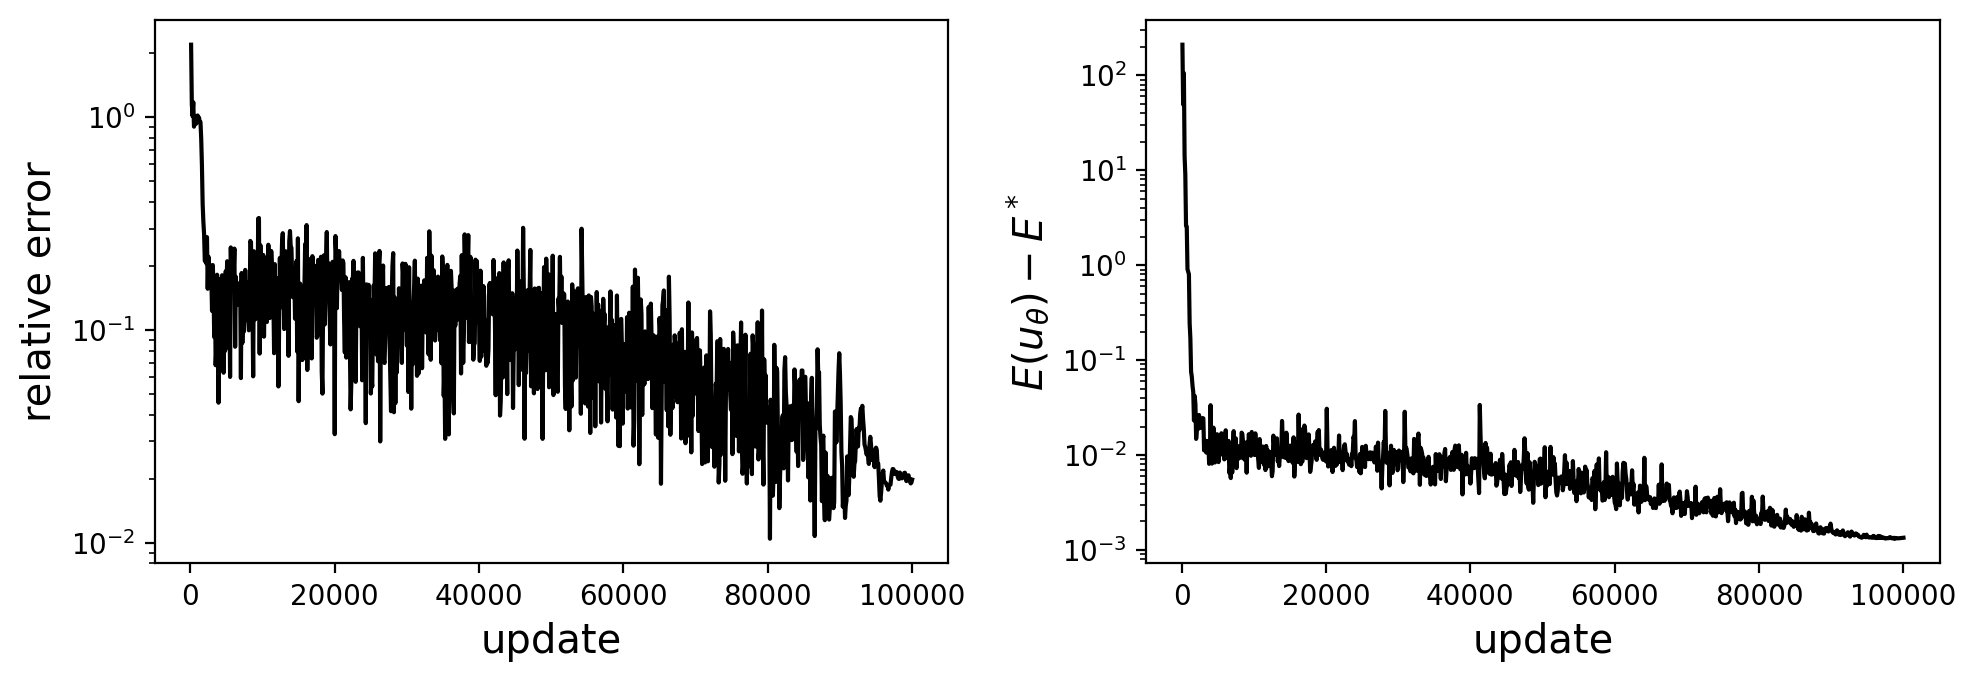

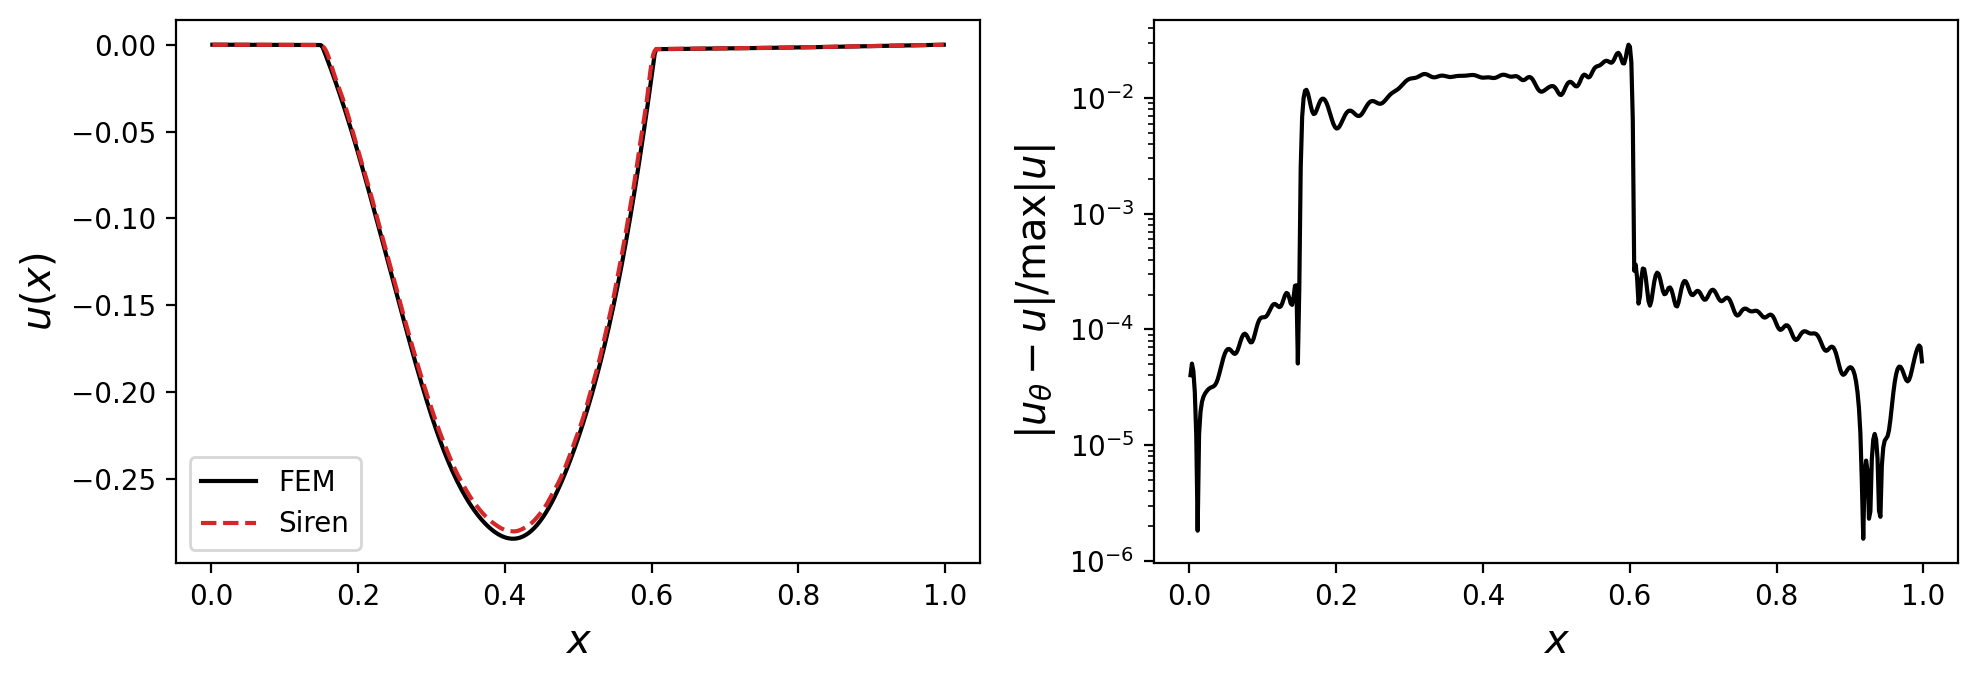

In [9]:
sample = 12
model, errors, training_time = train(sample, random.PRNGKey(45))
plot_results(sample, model, errors)

## Sample 3

The same training procedure with a different coefficient $a$ and right-hand side $f$. The network is trained from scratch, since it is specific to the pair $(a, f)$.

Training time: 12.5 s


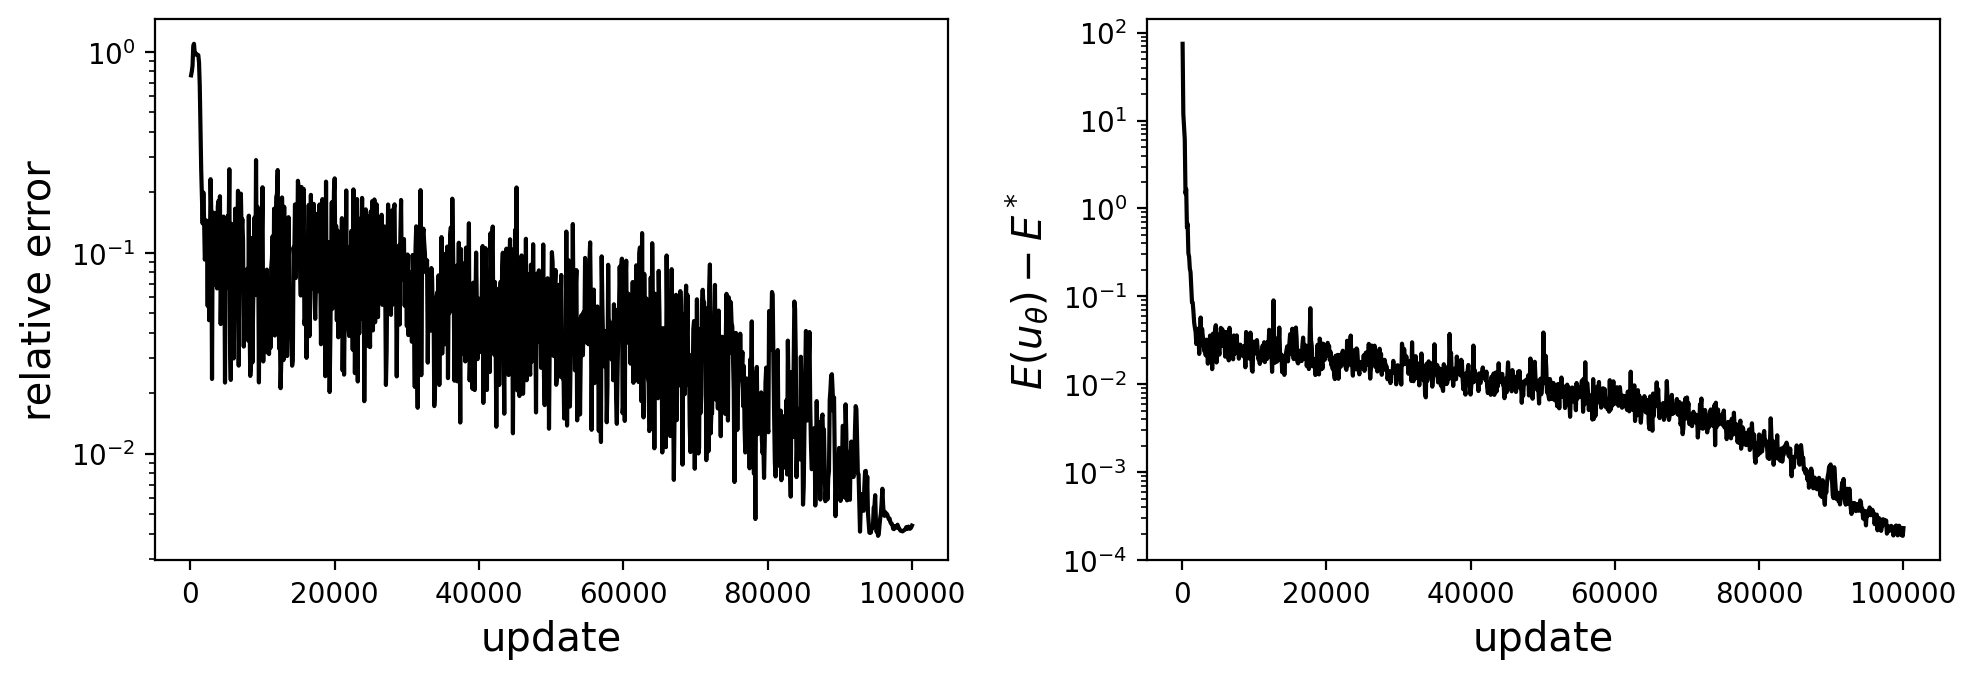

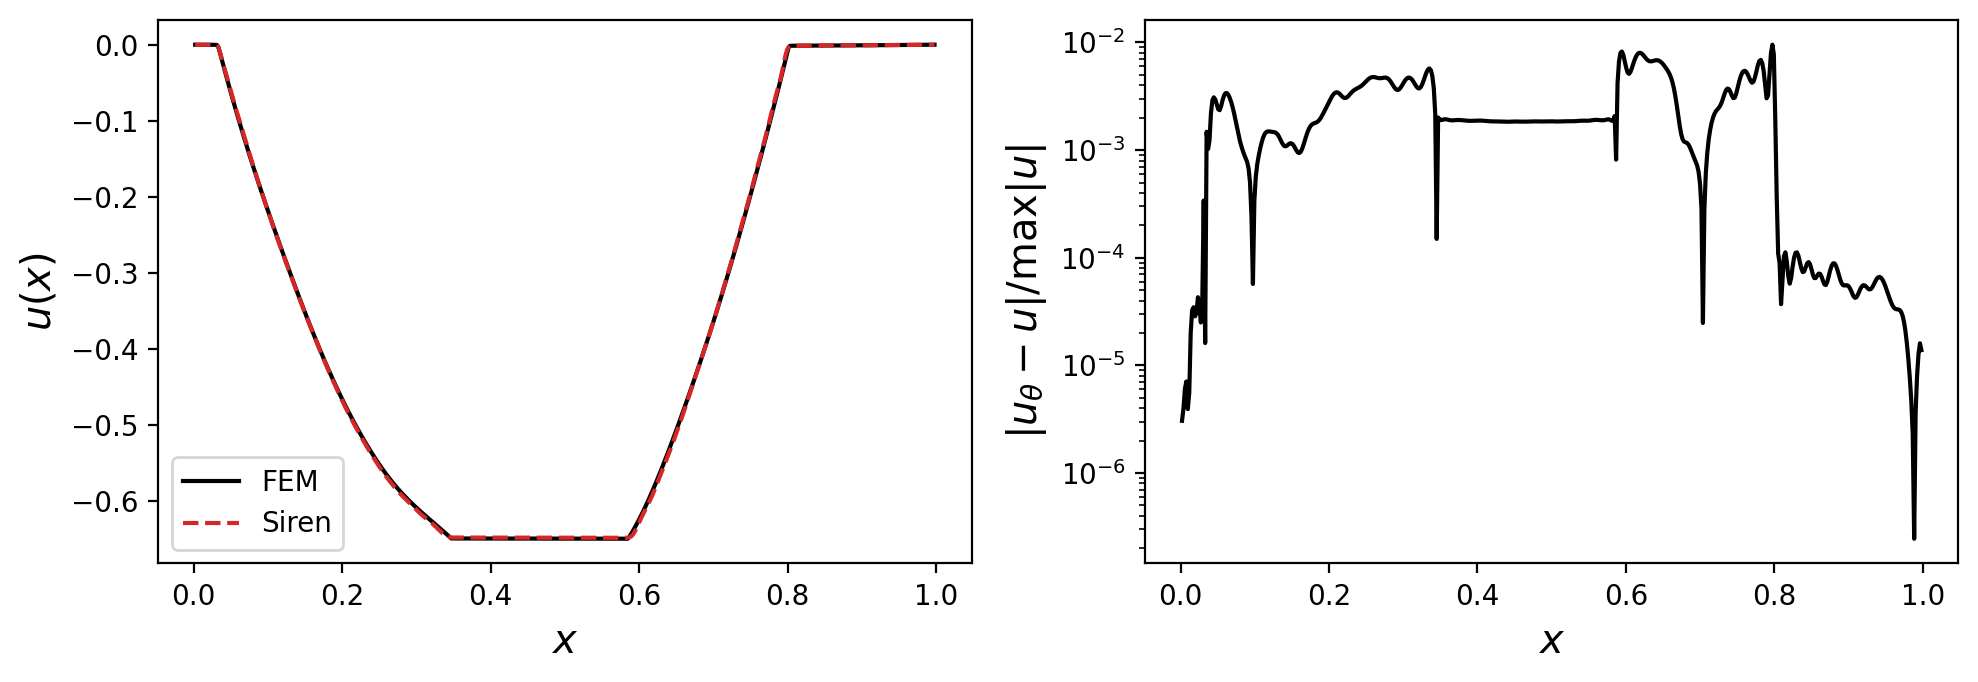

In [10]:
sample = 3
model, errors, training_time = train(sample, random.PRNGKey(45))
plot_results(sample, model, errors)

## Solution time: FEM vs Deep Ritz

Let us compare the cost of getting the solution of one problem. For FEM it is the time of assembling the matrices and solving the linear system (dense matrices, as in the FEM notebook, with `jit` and after a warm-up call). For Deep Ritz it is the time of training, as measured above for the last sample (it includes the compilation of the training loop). Both run on the same device. For this comparison the FEM solver takes the coefficient on an element as the average of its two nodal values, so its output differs by about one percent from the stored reference solution, which does not matter for timing.

In [11]:
N = x.shape[1]
h = 1 / (N + 1)

@jit
def fem_solve(a, f):
    # element coefficients from the nodal values (the boundary elements take the end values)
    a_e = jnp.concatenate([a[:1], (a[:-1] + a[1:]) / 2, a[-1:]])
    K = (jnp.diag(a_e[:-1] + a_e[1:]) - jnp.diag(a_e[1:-1], k=1) - jnp.diag(a_e[1:-1], k=-1)) / h
    M = h / 6 * (4 * jnp.eye(N) + jnp.diag(jnp.ones(N - 1), k=1) + jnp.diag(jnp.ones(N - 1), k=-1))
    return jnp.linalg.solve(K, M @ f)

def timeit(fn, *args, n_repeat=100):
    fn(*args).block_until_ready()  # warm-up (compilation)
    start = time.time()
    for _ in range(n_repeat):
        fn(*args).block_until_ready()
    return (time.time() - start) / n_repeat

fem_time = timeit(fem_solve, a[sample], f[sample])
fem_batch_time = timeit(jit(vmap(fem_solve)), a[:100], f[:100], n_repeat=10) / 100  # per problem

print("Time per problem")
print(f"  FEM (single solve):          {1e3 * fem_time:9.2f} ms")
print(f"  FEM (100 solves in a batch): {1e3 * fem_batch_time:9.2f} ms")
print(f"  Deep Ritz (training):        {1e3 * training_time:9.0f} ms")
print(f"Deep Ritz / FEM: {training_time / fem_time:.0f}x")

Time per problem
  FEM (single solve):               1.58 ms
  FEM (100 solves in a batch):      0.16 ms
  Deep Ritz (training):            12512 ms
Deep Ritz / FEM: 7915x


**Below are the analysis of Claude.**

For this problem FEM wins by a wide margin, by several orders of magnitude, and this is expected:

- **FEM** solves a single (here tridiagonal, so cheap even when stored densely) linear system. Its cost is fixed and predictable, does not depend on the coefficient, and the error is controlled by the mesh size ($O(h^2)$ for linear elements).
- **Deep Ritz** needs $10^5$ gradient evaluations through the network, and the quality of the result depends on the optimisation: the error is limited by how well the loss was minimised, not by a discretisation parameter, and it needs tuning (`s0`, the learning rate schedule, the number of updates). Moreover, the network is specific to one pair $(a(x), f(x))$, so every new problem requires a new training. The batched FEM line shows that the gap only grows when many problems have to be solved.

The comparison is deliberately unfavourable for the network, because a one-dimensional linear problem on a regular grid is the ideal case for FEM. The advantages of PINNs lie elsewhere: they are mesh-free, are not affected by the curse of dimensionality in the same way as grid-based methods, can handle complex geometries, and make it easy to combine the equation with measurement data (inverse problems). Another way to use neural networks is to pay the cost once: operator learning, which we consider next, trains a network on many pairs $(a(x), f(x))\to u(x)$, after which the solution of a new problem is a single forward pass.

*Note:* the absolute numbers depend on the hardware (here a GPU, where small dense solves are dominated by latency) and on the implementation, so the ratio matters more than the values.

**And here is what I have to reply to that.**

I do not think PINNs are good options for anything low-dimensional. In high dimensions, I agree they can be more efficient (although this is debatable, because classical methods tailored to this setting also exist).

The geometry pitch can often be found in PINN papers and repositories and is wildly exaggerated. First, classical meshfree methods exist if you need them. They will be vastly more efficient because they do not rely on the solutions of non-convex optimisation problems. Second, the complex geometry will still need to be formulated somehow: surfaces will be triangulated, points where the solution changes rapidly need to be tracked, and the insides and outsides of bodies will need to be specified.

As for inverse problems, I do not really believe PINNs are beneficial here. PINNs do not provide any means for explicit regularisation. Besides that, information about priors cannot be efficiently communicated to PINNs. They sure can help in some narrow classes of inverse problems, but for more serious standard cases (e.g., tomography, full waveform inversion), it is blasphemy to rely on PINNs.

I also want to add that the accuracy of PINNs is so poor that numerical analysts sometimes cry when they see it.

**Claude's comment on the reply.**

I agree with most of it, and this notebook is itself evidence for the main point: in our run the training took thousands of times longer than the FEM solve, and the accuracy is set by how well the optimisation went (choosing `s0` and decaying the learning rate changed the error by an order of magnitude in our experiments), whereas the FEM error is controlled by the mesh size alone.

A few remarks on the individual points:

- **Geometry.** Fair, and my bullet overstated it. What PINNs really avoid is *mesh generation*, not the *description of the geometry*: one still has to sample interior and boundary points, and the exact enforcement of boundary conditions we used here (the factor $\sin(\pi x)$) is easy only because the domain is an interval. In a complex domain it needs, e.g., a distance function or a penalty term, which brings back the usual loss-balancing difficulties.
- **Inverse problems.** I agree for the established applications such as tomography or full waveform inversion, where adjoint-based pipelines with explicit regularisation are mature. One nuance: a penalty on the unknown field (Tikhonov, total variation) *can* be added to the PINN loss, so I would say that regularisation is hard to control rather than absent. Its effect is entangled with the optimiser and the spectral bias of the network, there are no convergence guarantees, and there is no natural way to include a prior or quantify uncertainty.
- **High dimensions.** I am not sure about the current evidence either. For linear parabolic problems, Feynman–Kac Monte Carlo needs no training and is a strong baseline, so a fair comparison has to be made against such methods and not against a grid.

If you want the tutorial to be balanced for readers, I would rewrite my paragraph on the advantages of PINNs to say that the case for them is narrow, and cite a benchmark that supports your point, for example T. Grossmann, U. Komorowska, J. Latz, C.-B. Schönlieb, *Can Physics-Informed Neural Networks beat the Finite Element Method?* (arXiv:2302.04107; please verify the reference before using it).